# Módulo 4: Compresión de la Información de Imagen

**Objetivo:** Evaluar algoritmos de compresión con y sin pérdida
sobre imágenes del registro pupilar.

Se comparan Huffman, Run-Length Encoding (RLE) y JPEG,
evaluando la tasa de compresión, la fidelidad de reconstrucción
mediante PSNR y SSIM y el efecto sobre la estimación
del diámetro pupilar.

In [37]:
import sys
sys.path.append("..")

import heapq
from collections import Counter
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config import VIDEO_PATH
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from skimage.measure import regionprops, label
from src.segmentacion import segmentar_pupila

In [19]:
def comprimir_huffman(imagen):
    datos = imagen.flatten().tolist()
    frecuencias = Counter(datos)

    # Construcción del árbol de Huffman
    heap = []
    contador = 0

    for simbolo, frecuencia in frecuencias.items():
        heapq.heappush(heap, (frecuencia, contador, simbolo))
        contador += 1

    while len(heap) > 1:
        f1, _, nodo1 = heapq.heappop(heap)
        f2, _, nodo2 = heapq.heappop(heap)

        heapq.heappush(
            heap, (f1 + f2, contador, (nodo1, nodo2))
        )
        contador += 1

    arbol = heap[0][2]

    # Generación de códigos
    codigos = {}

    def recorrer(nodo, codigo=""):
        if isinstance(nodo, int):
            codigos[nodo] = codigo or "0"
        else:
            recorrer(nodo[0], codigo + "0")
            recorrer(nodo[1], codigo + "1")

    recorrer(arbol)

    # Codificación
    bits = "".join(codigos[pixel] for pixel in datos)

    # Decodificación
    inverso = {codigo: pixel for pixel, codigo in codigos.items()}

    reconstruidos = []
    actual = ""

    for bit in bits:
        actual += bit
        if actual in inverso:
            reconstruidos.append(inverso[actual])
            actual = ""

    reconstruida = np.array(
        reconstruidos, dtype=np.uint8
    ).reshape(imagen.shape)

    # Ratio teórico del flujo de datos
    bits_original = imagen.size * 8
    bits_comprimidos = len(bits)

    ratio = bits_original / bits_comprimidos

    return reconstruida, ratio, bits_comprimidos



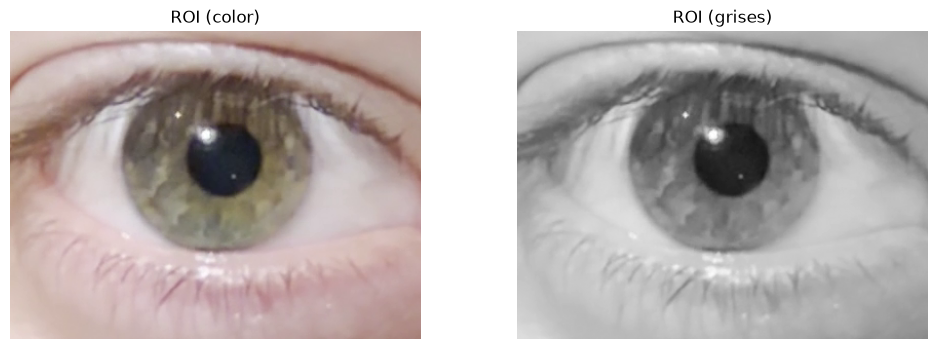

In [20]:
# Mismo frame y ROI que en el Módulo 1
FRAME_IDX = 778
x, y, w, h = 300, 950, 400, 300

# Leemos el frame elegido del video
cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

# Pasamos de BGR (formato de OpenCV) a RGB y recortamos la ROI
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
roi = frame_rgb[y:y+h, x:x+w]

# Versión en escala de grises: es la que usan la mayoría de los métodos
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(roi)
axes[0].set_title("ROI (color)")
axes[1].imshow(roi_gris, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("ROI (grises)")
for ax in axes:
    ax.axis("off")
plt.show()

In [26]:
# Aplicación de Huffman sobre la ROI
recon_huffman, ratio_huffman, bits_huffman = comprimir_huffman(roi_gris)

# Métricas
if np.array_equal(roi_gris, recon_huffman):
    psnr_huffman = float("inf")
else:
    psnr_huffman = peak_signal_noise_ratio(
        roi_gris, recon_huffman, data_range=255
    )

ssim_huffman = structural_similarity(
    roi_gris, recon_huffman, data_range=255
)

print(f"Ratio Huffman: {ratio_huffman:.3f}:1")
print(f"PSNR: {psnr_huffman}")
print(f"SSIM: {ssim_huffman:.4f}")
print("Reconstrucción exacta:",
      np.array_equal(roi_gris, recon_huffman))

Ratio Huffman: 1.137:1
PSNR: inf
SSIM: 1.0000
Reconstrucción exacta: True


## RLE horizontal y vertical
RLE es un algoritmo de compresión sin pérdida que reemplaza secuencias de valores iguales por pares (valor, cantidad).

In [27]:
def comprimir_rle(imagen, orientacion="horizontal"):
    if orientacion == "horizontal":
        datos = imagen.flatten()
    elif orientacion == "vertical":
        datos = imagen.T.flatten()
    else:
        raise ValueError("Orientación no válida")

    # Codificación RLE: pares (intensidad, cantidad)
    pares = []
    valor_actual = int(datos[0])
    cantidad = 1

    for valor in datos[1:]:
        valor = int(valor)

        if valor == valor_actual and cantidad < 65535:
            cantidad += 1
        else:
            pares.append((valor_actual, cantidad))
            valor_actual = valor
            cantidad = 1

    pares.append((valor_actual, cantidad))

    # Reconstrucción
    reconstruidos = np.repeat(
        [valor for valor, cantidad in pares],
        [cantidad for valor, cantidad in pares]
    ).astype(np.uint8)

    if orientacion == "horizontal":
        reconstruccion = reconstruidos.reshape(imagen.shape)
    else:
        reconstruccion = reconstruidos.reshape(imagen.T.shape).T

    # Estimación: 8 bits para intensidad + 16 para cantidad
    bits_originales = imagen.size * 8
    bits_comprimidos = len(pares) * 24
    ratio = bits_originales / bits_comprimidos

    return reconstruccion, ratio, len(pares)

In [28]:
recon_h, ratio_h, pares_h = comprimir_rle(
    roi_gris, "horizontal"
)

recon_v, ratio_v, pares_v = comprimir_rle(
    roi_gris, "vertical"
)

print("RLE HORIZONTAL")
print(f"Ratio: {ratio_h:.3f}:1")
print("Reconstrucción exacta:", np.array_equal(roi_gris, recon_h))

print("\nRLE VERTICAL")
print(f"Ratio: {ratio_v:.3f}:1")
print("Reconstrucción exacta:", np.array_equal(roi_gris, recon_v))

RLE HORIZONTAL
Ratio: 0.496:1
Reconstrucción exacta: True

RLE VERTICAL
Ratio: 0.475:1
Reconstrucción exacta: True


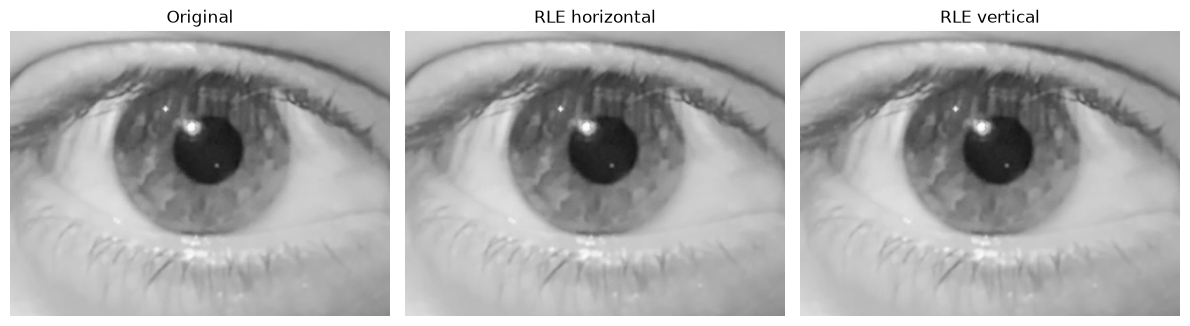

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

imagenes = [roi_gris, recon_h, recon_v]
titulos = ["Original", "RLE horizontal", "RLE vertical"]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

La compresión RLE, tanto horizontal como vertical, permitió reconstruir la imagen sin pérdida de información, conservando las características morfológicas de la pupila. Sin embargo, ambos métodos presentaron ratios de compresión inferiores a 1, indicando un aumento del tamaño de almacenamiento. Esto se atribuye a la variabilidad de intensidades de la imagen, que limita la formación de secuencias largas de píxeles idénticos.

## Compresión JPEG
Se aplicó compresión JPEG sobre la región de interés (ROI) en escala de grises, utilizando distintos factores de calidad (Q = 90, 50, 10 y 5). A diferencia de Huffman y RLE, JPEG es un método de compresión con pérdida, por lo que permite reducir el tamaño de almacenamiento a costa de introducir distorsiones en la imagen reconstruida.

Para cada nivel de calidad se calculó el ratio de compresión, PSNR y SSIM, con el objetivo de evaluar la relación entre la reducción del tamaño y la preservación de la información visual. Además, se compararon las imágenes reconstruidas para identificar posibles artefactos de compresión, especialmente en los bordes de la pupila, relevantes para su posterior segmentación y análisis morfológico.

In [32]:
calidades = [90, 50, 10, 5]
resultados_jpeg = []
imagenes_jpeg = {}

for Q in calidades:
    # Comprimir con calidad Q
    _, buffer = cv2.imencode(
        ".jpg", roi_gris,
        [cv2.IMWRITE_JPEG_QUALITY, Q]
    )

    # Descomprimir
    reconstruida = cv2.imdecode(buffer, cv2.IMREAD_GRAYSCALE)

    # Calcular métricas
    ratio = roi_gris.nbytes / buffer.nbytes
    psnr = peak_signal_noise_ratio(roi_gris, reconstruida, data_range=255)
    ssim = structural_similarity(roi_gris, reconstruida, data_range=255)

    resultados_jpeg.append([Q, ratio, psnr, ssim])
    imagenes_jpeg[Q] = reconstruida

df_jpeg = pd.DataFrame(
    resultados_jpeg,
    columns=["Calidad Q", "Ratio", "PSNR (dB)", "SSIM"]
)

display(df_jpeg.round(3))

,Calidad Q,Ratio,PSNR (dB),SSIM
0,90,7.812,48.576,0.993
1,50,19.036,42.900,0.977
2,10,41.826,34.251,0.879
3,5,53.667,29.799,0.779


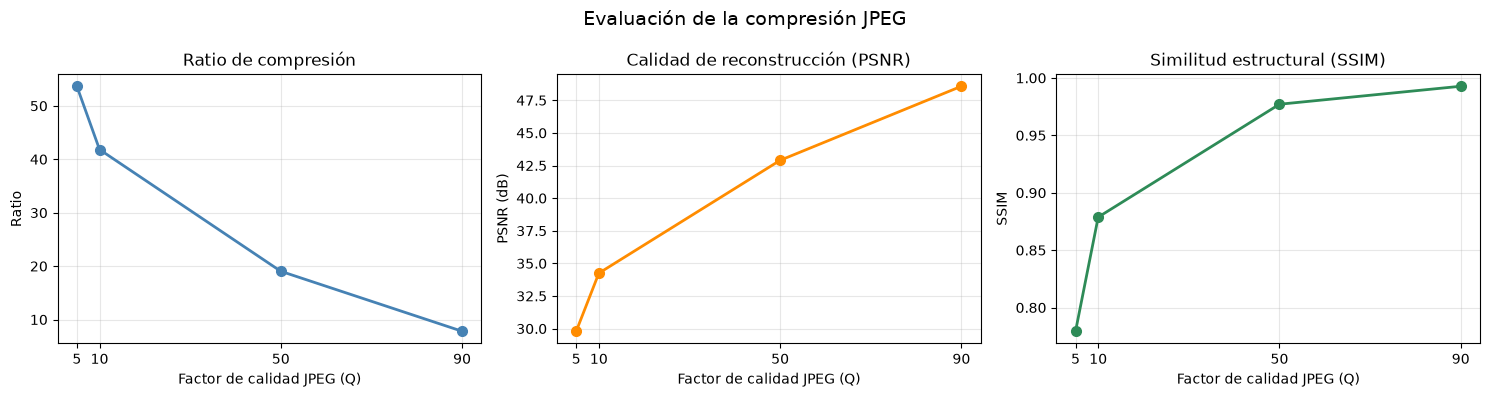

In [33]:
# Ordenar por calidad JPEG
df_plot = df_jpeg.sort_values("Calidad Q")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metricas = ["Ratio", "PSNR (dB)", "SSIM"]
titulos = [
    "Ratio de compresión",
    "Calidad de reconstrucción (PSNR)",
    "Similitud estructural (SSIM)"
]
colores = ["steelblue", "darkorange", "seagreen"]

for ax, metrica, titulo, color in zip(axes, metricas, titulos, colores):
    ax.plot(
        df_plot["Calidad Q"],
        df_plot[metrica],
        marker="o",
        linewidth=2,
        markersize=7,
        color=color
    )

    ax.set_title(titulo)
    ax.set_xlabel("Factor de calidad JPEG (Q)")
    ax.set_ylabel(metrica)
    ax.set_xticks([5, 10, 50, 90])
    ax.grid(True, alpha=0.3)

plt.suptitle("Evaluación de la compresión JPEG", fontsize=14)
plt.tight_layout()
plt.show()

Los resultados evidencian una relación inversa entre el factor de calidad JPEG y el ratio de compresión. Al disminuir Q de 90 a 5, el ratio aumenta de 7.812:1 a 53.667:1, mientras que el PSNR disminuye de 48.576 dB a 29.799 dB y el SSIM de 0.993 a 0.779.

Para calidades altas e intermedias (Q = 90 y Q = 50), se conserva una elevada similitud con la imagen original. En cambio, para calidades bajas (Q = 10 y Q = 5), se observa una mayor degradación de la información visual según las métricas calculadas.

Estos resultados permiten evaluar el compromiso entre eficiencia de almacenamiento y fidelidad de reconstrucción. Sin embargo, para determinar su impacto sobre el análisis biomédico, resulta necesario estudiar si las distorsiones introducidas por JPEG modifican la segmentación y la estimación del diámetro pupilar.

### Comparación PSNR y SSIM frente al ratio

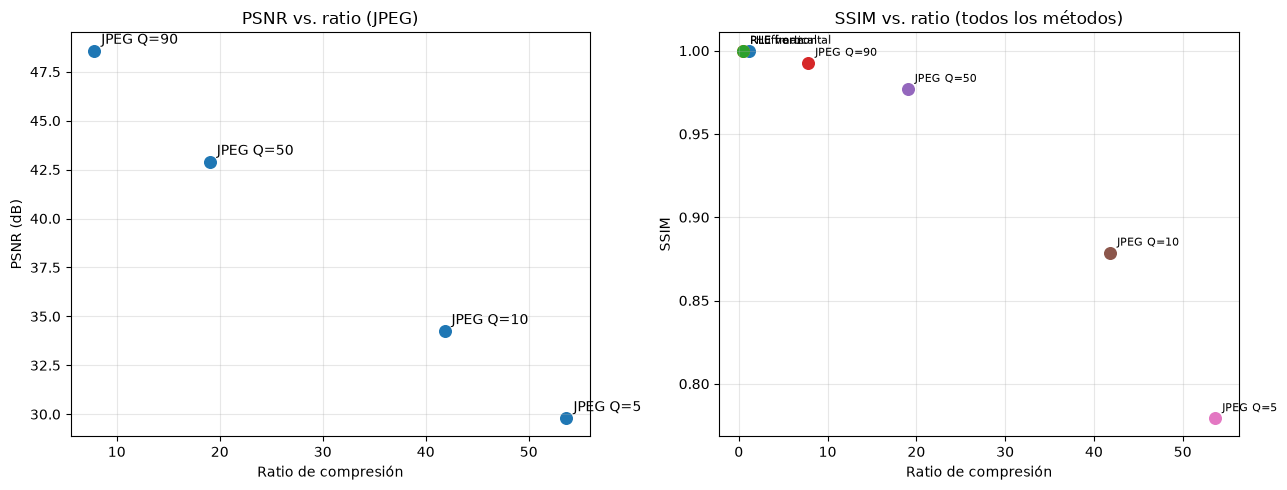

In [34]:
df_comparacion = pd.DataFrame({
    "Metodo": [
        "Huffman", "RLE horizontal", "RLE vertical",
        "JPEG Q=90", "JPEG Q=50", "JPEG Q=10", "JPEG Q=5"
    ],
    "Ratio": [
        ratio_huffman, ratio_h, ratio_v,
        *df_jpeg["Ratio"].tolist()
    ],
    "PSNR": [
        float("inf"), float("inf"), float("inf"),
        *df_jpeg["PSNR (dB)"].tolist()
    ],
    "SSIM": [
        1.0, 1.0, 1.0,
        *df_jpeg["SSIM"].tolist()
    ]
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

jpeg = df_comparacion[
    df_comparacion["Metodo"].str.startswith("JPEG")
]
sin_perdida = df_comparacion[
    ~df_comparacion["Metodo"].str.startswith("JPEG")
]

axes[0].scatter(jpeg["Ratio"], jpeg["PSNR"], s=70)
for _, fila in jpeg.iterrows():
    axes[0].annotate(
        fila["Metodo"], (fila["Ratio"], fila["PSNR"]),
        xytext=(5, 5), textcoords="offset points"
    )
axes[0].set_xlabel("Ratio de compresión")
axes[0].set_ylabel("PSNR (dB)")
axes[0].set_title("PSNR vs. ratio (JPEG)")
axes[0].grid(alpha=0.3)

for _, fila in df_comparacion.iterrows():
    axes[1].scatter(fila["Ratio"], fila["SSIM"], s=70)
    axes[1].annotate(
        fila["Metodo"], (fila["Ratio"], fila["SSIM"]),
        xytext=(5, 5), textcoords="offset points",
        fontsize=8
    )

axes[1].set_xlabel("Ratio de compresión")
axes[1].set_ylabel("SSIM")
axes[1].set_title("SSIM vs. ratio (todos los métodos)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Observación visual de los artefactos JPEG

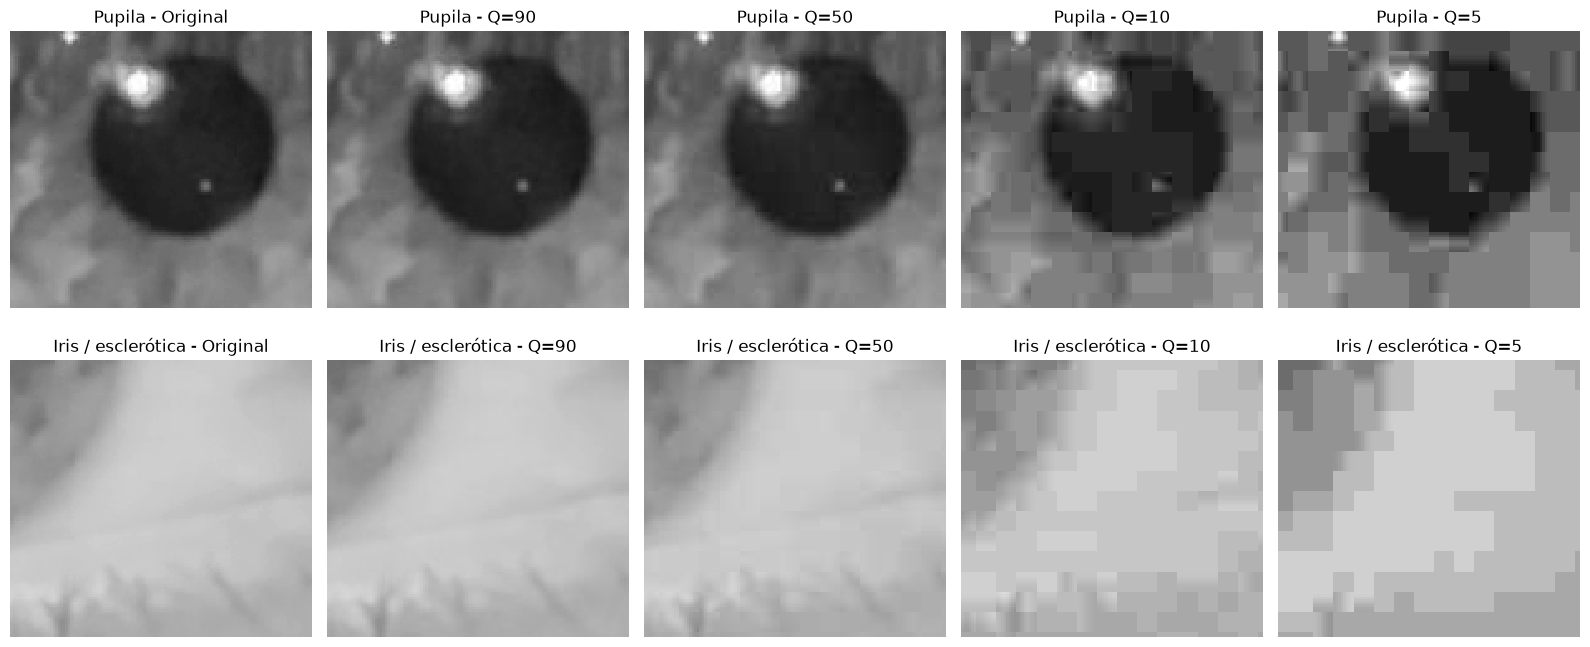

In [35]:
# Seleccionar dos regiones dentro de la ROI
# Ajustar las coordenadas según la posición de la pupila
regiones = {
    "Pupila": (140, 80, 120, 110),
    "Iris / esclerótica": (250, 140, 120, 110)
}

imagenes = {"Original": roi_gris}
imagenes.update({f"Q={q}": imagenes_jpeg[q] for q in [90, 50, 10, 5]})

fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for i, (nombre_region, (x, y, w, h)) in enumerate(regiones.items()):
    for j, (nombre, img) in enumerate(imagenes.items()):
        recorte = img[y:y+h, x:x+w]

        axes[i, j].imshow(
            recorte, cmap="gray",
            vmin=0, vmax=255,
            interpolation="nearest"
        )
        axes[i, j].set_title(f"{nombre_region} - {nombre}")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

La comparación visual de las imágenes reconstruidas evidencia que, para factores de calidad elevados (Q = 90 y Q = 50), se conserva gran parte de la información original, sin observarse artefactos de bloque significativos.

A partir de Q = 10, los artefactos de bloque se vuelven claramente perceptibles, intensificándose para Q = 5. Estos son especialmente notorios en las regiones relativamente uniformes del iris y la esclerótica, donde aparecen discontinuidades artificiales de intensidad y pérdida de textura.

En los bordes de la pupila se observa una degradación progresiva del contorno, que podría comprometer la precisión de los algoritmos de segmentación. Por lo tanto, aunque JPEG permite alcanzar elevados ratios de compresión, los factores de calidad bajos podrían afectar la confiabilidad de las mediciones morfológicas.

### ¿JPEG cambia el diámetro pupilar estimado?

In [40]:
def medir_diametro_pupilar(imagen):
    # El Módulo 3 segmentaba una ROI RGB.
    # Convertimos la imagen gris a 3 canales.
    if imagen.ndim == 2:
        imagen = cv2.cvtColor(imagen, cv2.COLOR_GRAY2RGB)

    # Segmentación del Módulo 2
    mascara = segmentar_pupila(imagen)

    # Cálculo del diámetro equivalente del Módulo 3
    regiones = regionprops(label(mascara > 0))

    if not regiones:
        return np.nan

    props = max(regiones, key=lambda r: r.area)

    return props.equivalent_diameter_area

In [41]:
diametro_original = medir_diametro_pupilar(roi_gris)
diametro_q50 = medir_diametro_pupilar(imagenes_jpeg[50])
diametro_q10 = medir_diametro_pupilar(imagenes_jpeg[10])

df_diametros = pd.DataFrame({
    "Imagen": ["Original", "JPEG Q=50", "JPEG Q=10"],
    "Diámetro (px)": [
        diametro_original,
        diametro_q50,
        diametro_q10
    ]
})

df_diametros["Error relativo (%)"] = (
    abs(df_diametros["Diámetro (px)"] - diametro_original)
    / diametro_original * 100
)

display(df_diametros.round(3))

,Imagen,Diámetro (px),Error relativo (%)
0,Original,73.240,0.000
1,JPEG Q=50,73.319,0.107
2,JPEG Q=10,73.249,0.012


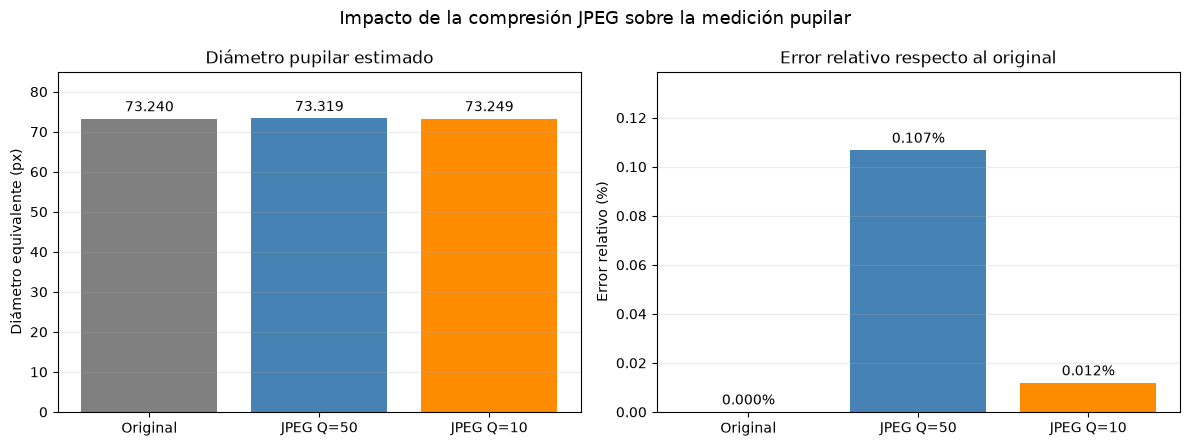

In [42]:
# Datos calculados previamente
imagenes = ["Original", "JPEG Q=50", "JPEG Q=10"]
diametros = [diametro_original, diametro_q50, diametro_q10]

errores = [
    abs(d - diametro_original) / diametro_original * 100
    for d in diametros
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico 1: diámetros pupilares
barras1 = axes[0].bar(
    imagenes, diametros,
    color=["gray", "steelblue", "darkorange"]
)

axes[0].set_title("Diámetro pupilar estimado")
axes[0].set_ylabel("Diámetro equivalente (px)")
axes[0].set_ylim(0, 85)
axes[0].bar_label(barras1, fmt="%.3f", padding=3)
axes[0].grid(axis="y", alpha=0.25)

# Gráfico 2: error relativo
barras2 = axes[1].bar(
    imagenes, errores,
    color=["gray", "steelblue", "darkorange"]
)

axes[1].set_title("Error relativo respecto al original")
axes[1].set_ylabel("Error relativo (%)")
axes[1].set_ylim(0, max(errores) * 1.3)
axes[1].bar_label(barras2, fmt="%.3f%%", padding=3)
axes[1].grid(axis="y", alpha=0.25)

plt.suptitle(
    "Impacto de la compresión JPEG sobre la medición pupilar",
    fontsize=13
)

plt.tight_layout()
plt.show()

Se evaluó el efecto de la compresión JPEG sobre la estimación del diámetro equivalente de la pupila, aplicando el mismo procedimiento de segmentación y medición a la imagen original y a las reconstrucciones con Q = 50 y Q = 10.

El diámetro original fue de 73.240 píxeles, mientras que las imágenes comprimidas presentaron valores de 73.319 píxeles para Q = 50 y 73.249 píxeles para Q = 10, correspondientes a errores relativos del 0.107 % y 0.012 %, respectivamente.

Los resultados indican que, para la imagen analizada, la compresión JPEG no produjo modificaciones relevantes en el diámetro pupilar estimado, incluso cuando la calidad visual disminuyó considerablemente.

Esto sugiere que el método de segmentación utilizado presenta cierta robustez frente a los artefactos de compresión. Sin embargo, esta observación se limita a la ROI evaluada y no permite garantizar el mismo comportamiento en otros frames o condiciones de adquisición.

## Conclusión

Se compararon distintos métodos de compresión de imágenes aplicados a una región de interés ocular. Huffman y RLE permitieron reconstruir exactamente la imagen original, aunque Huffman presentó una mayor eficiencia de almacenamiento, mientras que RLE generó un aumento del tamaño de los datos.

Por su parte, JPEG permitió alcanzar ratios de compresión considerablemente superiores, a costa de una reducción progresiva del PSNR y SSIM. Los artefactos de bloque se hicieron claramente visibles a partir de Q = 10, especialmente en regiones relativamente uniformes, mientras que en los bordes pupilares se observaron alteraciones que podrían afectar su segmentación.

Sin embargo, la evaluación del diámetro equivalente mostró errores inferiores al 0.11 % para Q = 50 y Q = 10. Esto indica que, en la imagen analizada, la pérdida de calidad visual no se tradujo en una alteración significativa de la medición pupilar.

En consecuencia, JPEG podría representar una alternativa eficiente para reducir los requerimientos de almacenamiento, siempre que se evalúe su impacto sobre las mediciones biomédicas y se valide su comportamiento sobre un conjunto representativo de imágenes.